# scikit-learn : machine learning in practice
    1. the API            ---> estimators , fit / predict / transform , hyperparameters vs learned_ attributes
    2. honest evaluation  ---> train / test , cross-validation , the leakage trap , Pipeline
    3. regression         ---> linear , Ridge , Lasso , metrics , coefficient paths
    4. classification     ---> six model families compared with cross-validation
    5. trees & ensembles  ---> decision tree , depth vs overfitting , random forest , gradient boosting
    6. tuning             ---> GridSearchCV , RandomizedSearchCV , learning curves
    7. imbalanced data    ---> class_weight , threshold tuning
    8. interpretation     ---> permutation importance , partial dependence
    9. unsupervised       ---> k-means , silhouette , DBSCAN , Isolation Forest
   10. persistence        ---> joblib
   11. final project      ---> an end-to-end churn model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from cycler import cycler

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.prop_cycle": cycler(color=SERIES), "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2,
    "legend.frameon": False, "legend.fontsize": 9, "figure.constrained_layout.use": True,
})
sns.set_palette(SERIES)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. One API for every model
    model = Estimator(hyperparameters)    ---> choices YOU make before training
    model.fit(X, y)                       ---> learns from data
    model.coef_ , model.classes_ ...      ---> learned values end with "_"
    model.predict(X_new) / predict_proba  ---> predictors
    scaler.transform(X)                   ---> transformers

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target                     # 569 tumours , 30 features ; 1 = benign , 0 = malignant
print(X.shape, "| classes:", {str(n): int(c) for n, c in zip(data.target_names, np.bincount(y))})

scaler = StandardScaler()                          # a TRANSFORMER
print("before fit , has mean_ ?", hasattr(scaler, "mean_"))
Xs = scaler.fit_transform(X)
print("after fit  , mean_[:3] =", scaler.mean_[:3].round(2), "| scale_[:3] =", scaler.scale_[:3].round(2))

clf = LogisticRegression(C=1.0, max_iter=1000)     # a PREDICTOR ; C is a hyperparameter
clf.fit(Xs, y)
print("learned: coef_", clf.coef_.shape, "| intercept_", clf.intercept_.round(2), "| classes_", clf.classes_)
print("predict      :", clf.predict(Xs[:5]))
print("predict_proba:\n", clf.predict_proba(Xs[:3]).round(3))
print("score (accuracy on the SAME data):", round(clf.score(Xs, y), 3))

(569, 30) | classes: {'malignant': 212, 'benign': 357}
before fit , has mean_ ? False
after fit  , mean_[:3] = [14.13 19.29 91.97] | scale_[:3] = [ 3.52  4.3  24.28]
learned: coef_ (1, 30) | intercept_ [0.22] | classes_ [0 1]
predict      : [0 0 0 0 0]
predict_proba:
 [[1. 0.]
 [1. 0.]
 [1. 0.]]
score (accuracy on the SAME data): 0.988


In [3]:
from sklearn.base import clone

print(clf.get_params()["C"], "|", clf.set_params(C=0.1).get_params()["C"])
fresh = clone(clf)                                  # same hyperparameters , NOT fitted
print("clone has coef_ ?", hasattr(fresh, "coef_"))
try:
    fresh.predict(Xs[:1])
except Exception as e:
    print(type(e).__name__, ":", str(e)[:70], "...")

1.0 | 0.1
clone has coef_ ? False
NotFittedError : This LogisticRegression instance is not fitted yet. Call 'fit' with ap ...


## 2. Honest evaluation
    never judge a model on the data it was trained on

In [4]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_tr, y_tr)
print("train accuracy:", round(model.score(X_tr, y_tr), 3), "| test accuracy:", round(model.score(X_te, y_te), 3))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scores = cross_val_score(model, X_tr, y_tr, cv=cv)
print("5-fold CV:", scores.round(3), "-> mean", round(scores.mean(), 3), "+-", round(scores.std(), 3))

splits = [train_test_split(X, y, test_size=0.25, stratify=y, random_state=s) for s in range(20)]
single = [clone(model).fit(a, c).score(b, d) for a, b, c, d in splits]
print(f"20 different single splits : min {min(single):.3f} , max {max(single):.3f}  <- one split is a noisy estimate")

train accuracy: 0.991 | test accuracy: 0.958
5-fold CV: [1.    0.976 0.976 0.988 0.965] -> mean 0.981 +- 0.012
20 different single splits : min 0.958 , max 0.993  <- one split is a noisy estimate


In [5]:
# the LEAKAGE trap : choosing features with ALL the data , then cross-validating
from sklearn.feature_selection import SelectKBest, f_classif

rng = np.random.default_rng(0)
X_noise = rng.normal(size=(100, 5000))               # 5000 random features
y_noise = rng.integers(0, 2, 100)                     # random labels : nothing to learn

top = SelectKBest(f_classif, k=20).fit(X_noise, y_noise)
leaky = cross_val_score(LogisticRegression(max_iter=1000), top.transform(X_noise), y_noise, cv=5)

honest_model = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(honest_model, X_noise, y_noise, cv=5)

print("selection OUTSIDE cv :", round(leaky.mean(), 3), "<- looks like a great model")
print("selection INSIDE  cv :", round(honest.mean(), 3), "<- the truth : chance level")

selection OUTSIDE cv : 0.85 <- looks like a great model
selection INSIDE  cv : 0.48 <- the truth : chance level


## 3. Regression : predicting a number
    diabetes dataset : 442 patients , 10 measurements -> disease progression after one year

In [6]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

diab = load_diabetes(as_frame=True)
Xd, yd = diab.data, diab.target
print(Xd.shape, "| target range:", yd.min(), "->", yd.max())

models = {
    "mean (baseline)": DummyRegressor(),
    "linear": LinearRegression(),
    "ridge a=1": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "lasso a=1": make_pipeline(StandardScaler(), Lasso(alpha=1.0)),
}
rows = []
for name, m in models.items():
    r = cross_validate(m, Xd, yd, cv=5, scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    rows.append({"model": name, "MAE": -r["test_neg_mean_absolute_error"].mean(),
                 "RMSE": -r["test_neg_root_mean_squared_error"].mean(), "R2": r["test_r2"].mean()})
print(pd.DataFrame(rows).set_index("model").round(3))

(442, 10) | target range: 25.0 -> 346.0
                    MAE    RMSE     R2
model                                 
mean (baseline)  66.046  77.264 -0.028
linear           44.276  54.692  0.482
ridge a=1        44.265  54.699  0.482
lasso a=1        44.461  54.711  0.482


lasso alpha= 0.1 :  9 non-zero features -> ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']
lasso alpha=   1 :  7 non-zero features -> ['sex', 'bmi', 'bp', 's1', 's3', 's5', 's6']
lasso alpha=   5 :  5 non-zero features -> ['sex', 'bmi', 'bp', 's3', 's5']
lasso alpha=  20 :  3 non-zero features -> ['bmi', 'bp', 's5']


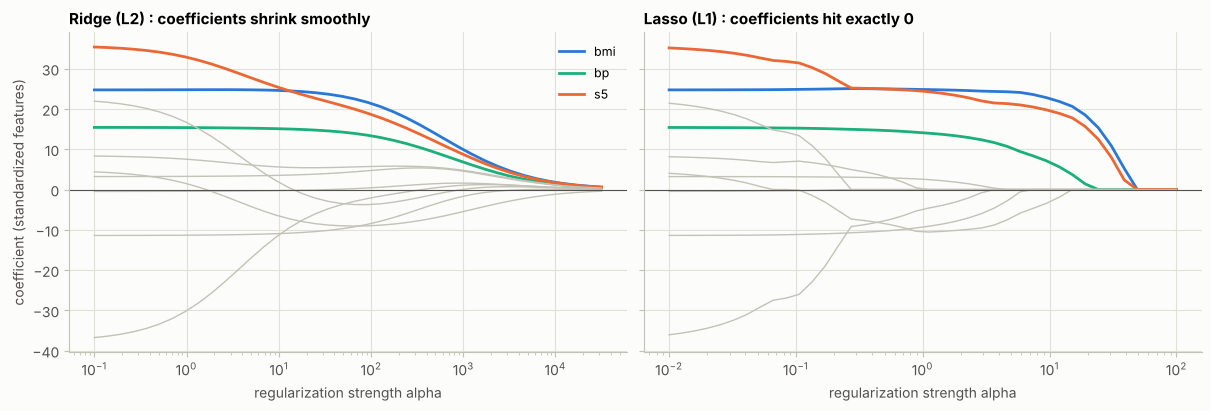

In [7]:
Xd_s = StandardScaler().fit_transform(Xd)
ridge_alphas, lasso_alphas = np.logspace(-1, 4.5, 40), np.logspace(-2, 2, 40)
ridge_path = np.array([Ridge(alpha=a).fit(Xd_s, yd).coef_ for a in ridge_alphas])
lasso_path = np.array([Lasso(alpha=a).fit(Xd_s, yd).coef_ for a in lasso_alphas])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, alphas, path, title in [(axes[0], ridge_alphas, ridge_path, "Ridge (L2) : coefficients shrink smoothly"),
                                (axes[1], lasso_alphas, lasso_path, "Lasso (L1) : coefficients hit exactly 0")]:
    for j, name in enumerate(Xd.columns):
        strong = name in ("bmi", "s5", "bp")
        ax.plot(alphas, path[:, j], color=SERIES[["bmi", "s5", "bp"].index(name)] if strong else AXIS,
                linewidth=2 if strong else 1, label=name if strong else None)
    ax.set_xscale("log")
    ax.axhline(0, color=INK2, linewidth=0.8)
    ax.set(title=title, xlabel="regularization strength alpha")
axes[0].set_ylabel("coefficient (standardized features)")
axes[0].legend(loc="upper right")
plt.show()

for a in [0.1, 1, 5, 20]:
    m = Lasso(alpha=a).fit(Xd_s, yd)
    print(f"lasso alpha={a:>4} : {np.sum(m.coef_ != 0):2d} non-zero features -> {list(Xd.columns[m.coef_ != 0])}")

test RMSE: 53.0 | target std: 78.8


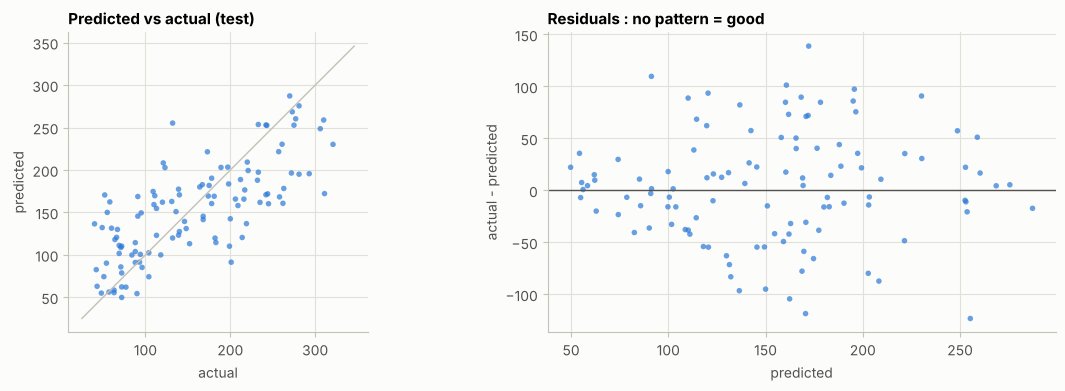

In [8]:
lin = LinearRegression().fit(X_tr_d := Xd.iloc[:330], y_tr_d := yd.iloc[:330])
pred = lin.predict(Xd.iloc[330:])
resid = yd.iloc[330:] - pred

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.scatter(yd.iloc[330:], pred, s=16, alpha=0.7, color=SERIES[0], edgecolor="none")
ax.plot([25, 346], [25, 346], color=AXIS, linewidth=1)
ax.set(title="Predicted vs actual (test)", xlabel="actual", ylabel="predicted", aspect="equal")
ax = axes[1]
ax.scatter(pred, resid, s=16, alpha=0.7, color=SERIES[0], edgecolor="none")
ax.axhline(0, color=INK2, linewidth=1)
ax.set(title="Residuals : no pattern = good", xlabel="predicted", ylabel="actual - predicted")
plt.show()
print("test RMSE:", round(np.sqrt(np.mean(resid ** 2)), 1), "| target std:", round(yd.iloc[330:].std(), 1))

## 4. Classification : six model families , one protocol

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import time

candidates = {
    "majority (baseline)": DummyClassifier(),
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN k=7": make_pipeline(StandardScaler(), KNeighborsClassifier(7)),
    "SVM rbf": make_pipeline(StandardScaler(), SVC()),
    "tree": DecisionTreeClassifier(random_state=0),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=0),
    "grad. boosting": HistGradientBoostingClassifier(random_state=0),
}
results = {}
for name, m in candidates.items():
    t0 = time.perf_counter()
    results[name] = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc")
    print(f"{name:20s} AUC {results[name].mean():.3f} +- {results[name].std():.3f}   ({time.perf_counter() - t0:.2f} s)")

majority (baseline)  AUC 0.500 +- 0.000   (0.02 s)
logistic             AUC 0.995 +- 0.007   (0.07 s)
KNN k=7              AUC 0.991 +- 0.009   (0.07 s)
SVM rbf              AUC 0.997 +- 0.004   (0.06 s)
tree                 AUC 0.926 +- 0.023   (0.06 s)
random forest        AUC 0.996 +- 0.004   (2.35 s)
grad. boosting       AUC 0.994 +- 0.007   (0.77 s)


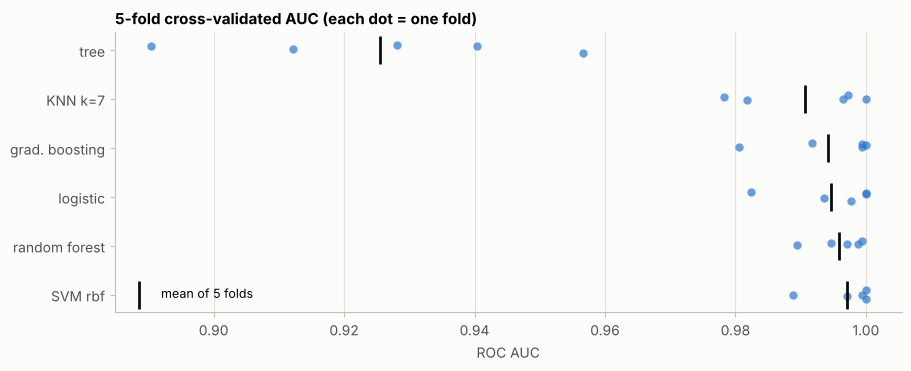

In [10]:
res = pd.DataFrame(results).melt(var_name="model", value_name="AUC")
order = res.groupby("model")["AUC"].mean().sort_values().index[1:]          # drop the baseline from the plot

fig, ax = plt.subplots(figsize=(9, 3.6))
sns.stripplot(res[res.model.isin(order)], y="model", x="AUC", order=order, color=SERIES[0], size=6, alpha=0.7, ax=ax)
means = res.groupby("model")["AUC"].mean()[order]
ax.scatter(means.values, range(len(order)), marker="|", s=400, color=INK, zorder=3, label="mean of 5 folds")
ax.set(title="5-fold cross-validated AUC (each dot = one fold)", xlabel="ROC AUC", ylabel="")
ax.legend(loc="lower left")
ax.grid(axis="y", visible=False)
plt.show()

## 5. Decision trees and ensembles

|--- worst perimeter <= 106.10
|   |--- worst concave points <= 0.13
|   |   |--- class: 1
|   |--- worst concave points >  0.13
|   |   |--- class: 0
|--- worst perimeter >  106.10
|   |--- worst concave points <= 0.14
|   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- class: 0

depth-2 tree test accuracy: 0.888


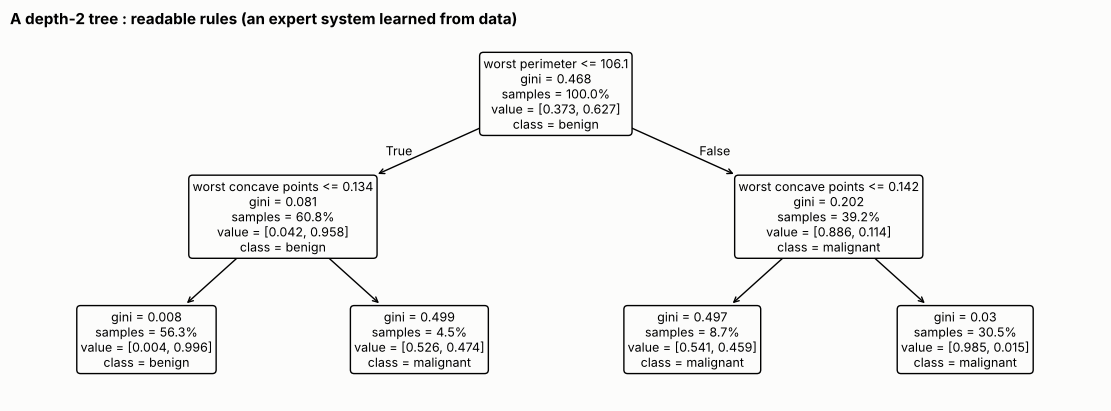

In [11]:
from sklearn.tree import plot_tree, export_text

small = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
print(export_text(small, feature_names=list(X.columns)))

fig, ax = plt.subplots(figsize=(11, 4))
plot_tree(small, feature_names=list(X.columns), class_names=list(data.target_names), filled=False,
          impurity=True, proportion=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("A depth-2 tree : readable rules (an expert system learned from data)")
plt.show()
print("depth-2 tree test accuracy:", round(small.score(X_te, y_te), 3))

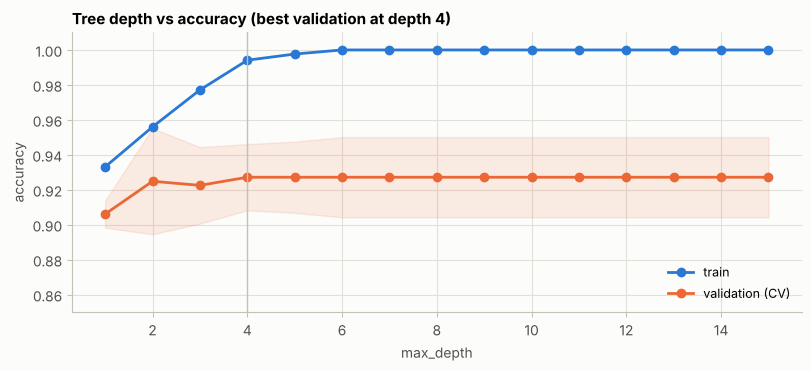

In [12]:
from sklearn.model_selection import validation_curve

depths = np.arange(1, 16)
tr_s, va_s = validation_curve(DecisionTreeClassifier(random_state=0), X_tr, y_tr,
                              param_name="max_depth", param_range=depths, cv=cv)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(depths, tr_s.mean(1), marker="o", label="train")
ax.plot(depths, va_s.mean(1), marker="o", label="validation (CV)")
ax.fill_between(depths, va_s.mean(1) - va_s.std(1), va_s.mean(1) + va_s.std(1), color=SERIES[1], alpha=0.12)
best_d = depths[va_s.mean(1).argmax()]
ax.axvline(best_d, color=AXIS, linewidth=1)
ax.set(title=f"Tree depth vs accuracy (best validation at depth {best_d})", xlabel="max_depth", ylabel="accuracy", ylim=(0.85, 1.01))
ax.legend(loc="lower right")
plt.show()

In [13]:
# variance : a single deep tree changes a lot with the data , a forest averages it away
rng = np.random.default_rng(1)
tree_scores, forest_scores = [], []
for seed in range(15):
    idx = rng.choice(len(X_tr), len(X_tr), replace=True)                # bootstrap sample
    tree_scores.append(DecisionTreeClassifier(random_state=seed).fit(X_tr.iloc[idx], y_tr.iloc[idx]).score(X_te, y_te))
    forest_scores.append(RandomForestClassifier(200, random_state=seed).fit(X_tr.iloc[idx], y_tr.iloc[idx]).score(X_te, y_te))
print(f"single tree  : mean {np.mean(tree_scores):.3f} , std {np.std(tree_scores):.3f}")
print(f"random forest: mean {np.mean(forest_scores):.3f} , std {np.std(forest_scores):.3f}")

gb = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.1, early_stopping=True,
                                    validation_fraction=0.2, n_iter_no_change=20, random_state=0).fit(X_tr, y_tr)
print("gradient boosting stopped after", gb.n_iter_, "of 500 trees | test accuracy", round(gb.score(X_te, y_te), 3))

single tree  : mean 0.915 , std 0.012
random forest: mean 0.942 , std 0.010
gradient boosting stopped after 103 of 500 trees | test accuracy 0.951


## 6. Hyperparameter tuning
    the search uses ONLY the training set (with inner CV) ; the test set is touched once , at the end

best params: {'svc__C': 10.0, 'svc__gamma': 0.01} | best CV AUC: 0.9968


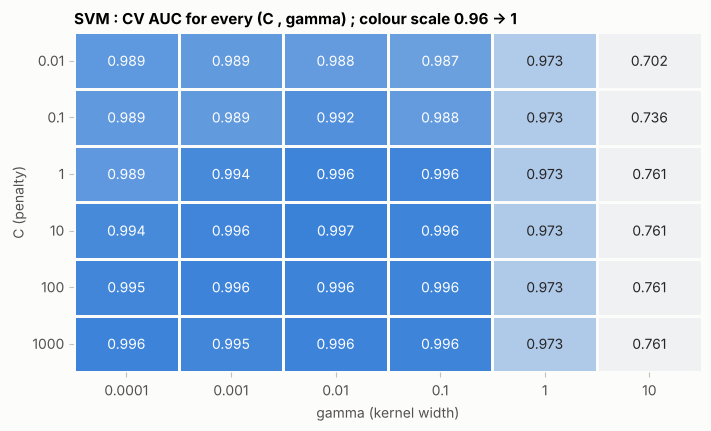

In [14]:
from sklearn.model_selection import GridSearchCV

svm = make_pipeline(StandardScaler(), SVC())
grid = {"svc__C": np.logspace(-2, 3, 6), "svc__gamma": np.logspace(-4, 1, 6)}      # step__parameter
search = GridSearchCV(svm, grid, cv=cv, scoring="roc_auc").fit(X_tr, y_tr)
print("best params:", {k: float(v) for k, v in search.best_params_.items()}, "| best CV AUC:", round(search.best_score_, 4))

table = pd.DataFrame(search.cv_results_).pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(table, annot=True, fmt=".3f", cmap=sns.light_palette(SERIES[0], as_cmap=True), cbar=False, vmin=0.96, vmax=1.0,
            linewidths=2, linecolor=SURFACE, ax=ax,
            xticklabels=[f"{g:g}" for g in table.columns], yticklabels=[f"{c:g}" for c in table.index])
ax.set(title="SVM : CV AUC for every (C , gamma) ; colour scale 0.96 -> 1", xlabel="gamma (kernel width)", ylabel="C (penalty)")
ax.tick_params(axis="y", rotation=0)
plt.show()

In [15]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

space = {"learning_rate": loguniform(0.01, 0.5), "max_depth": randint(2, 8),
         "min_samples_leaf": randint(5, 60), "l2_regularization": loguniform(1e-4, 10)}
rand = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=0), space, n_iter=25, cv=cv,
                          scoring="roc_auc", random_state=0).fit(X_tr, y_tr)
print("best:", {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in rand.best_params_.items()})
print("best CV AUC:", round(rand.best_score_, 4))

best: {'l2_regularization': 0.0178, 'learning_rate': 0.11, 'max_depth': 3, 'min_samples_leaf': 6}
best CV AUC: 0.9966


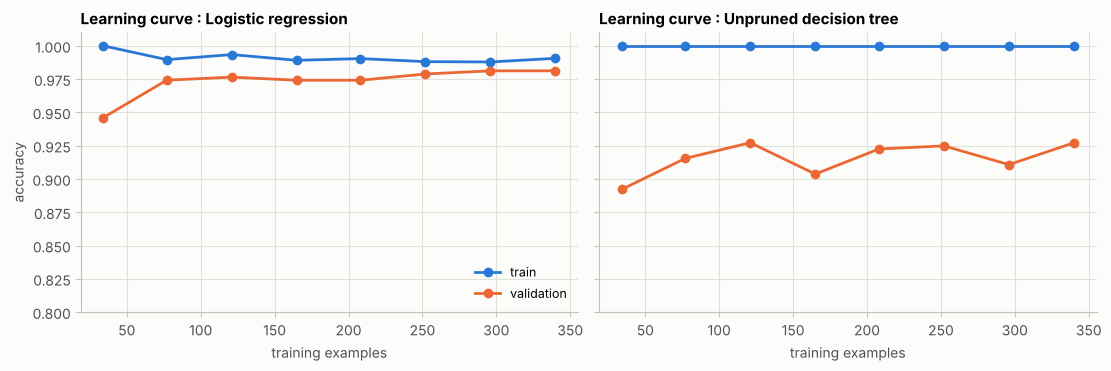

In [16]:
from sklearn.model_selection import learning_curve

sizes, tr_lc, va_lc = learning_curve(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_tr, y_tr,
                                     train_sizes=np.linspace(0.1, 1, 8), cv=cv)
sizes2, tr_lc2, va_lc2 = learning_curve(DecisionTreeClassifier(random_state=0), X_tr, y_tr,
                                        train_sizes=np.linspace(0.1, 1, 8), cv=cv)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, s, a, b, title in [(axes[0], sizes, tr_lc, va_lc, "Logistic regression"),
                           (axes[1], sizes2, tr_lc2, va_lc2, "Unpruned decision tree")]:
    ax.plot(s, a.mean(1), marker="o", label="train")
    ax.plot(s, b.mean(1), marker="o", label="validation")
    ax.set(title=f"Learning curve : {title}", xlabel="training examples", ylim=(0.8, 1.01))
axes[0].set_ylabel("accuracy")
axes[0].legend(loc="lower right")
plt.show()

## 7. Imbalanced classes : rare positives (fraud , failures , disease)

In [17]:
from sklearn.datasets import make_classification
from sklearn.metrics import classification_report, recall_score, precision_score, f1_score

Xi, yi = make_classification(n_samples=6000, n_features=12, n_informative=5, weights=[0.97], flip_y=0.01,
                             class_sep=1.6, random_state=3)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=0)
print("positive rate:", round(yi.mean(), 3))

always_no = DummyClassifier().fit(Xi_tr, yi_tr)
print("always 'no' accuracy:", round(always_no.score(Xi_te, yi_te), 3), " <- accuracy is useless here")

for cw in [None, "balanced"]:
    m = make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw, max_iter=1000)).fit(Xi_tr, yi_tr)
    p = m.predict(Xi_te)
    print(f"class_weight={str(cw):9s} precision {precision_score(yi_te, p, zero_division=0):.3f} recall {recall_score(yi_te, p):.3f} "
          f"F1 {f1_score(yi_te, p):.3f}")

positive rate: 0.037
always 'no' accuracy: 0.963  <- accuracy is useless here
class_weight=None      precision 0.833 recall 0.152 F1 0.256
class_weight=balanced  precision 0.145 recall 0.803 F1 0.245


In [18]:
from sklearn.model_selection import TunedThresholdClassifierCV

base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
tuned = TunedThresholdClassifierCV(base, scoring="f1", cv=5).fit(Xi_tr, yi_tr)
p = tuned.predict(Xi_te)
print("best threshold (by CV F1):", round(tuned.best_threshold_, 3))
print(classification_report(yi_te, p, target_names=["normal", "rare"], digits=3))

best threshold (by CV F1): 0.122
              precision    recall  f1-score   support

      normal      0.985     0.950     0.967      1734
        rare      0.320     0.621     0.423        66

    accuracy                          0.938      1800
   macro avg      0.653     0.786     0.695      1800
weighted avg      0.961     0.938     0.947      1800



## 8. What did the model learn ?

random_id : impurity rank 6 of 11 | permutation AUC drop -0.0038
test accuracy: 0.714


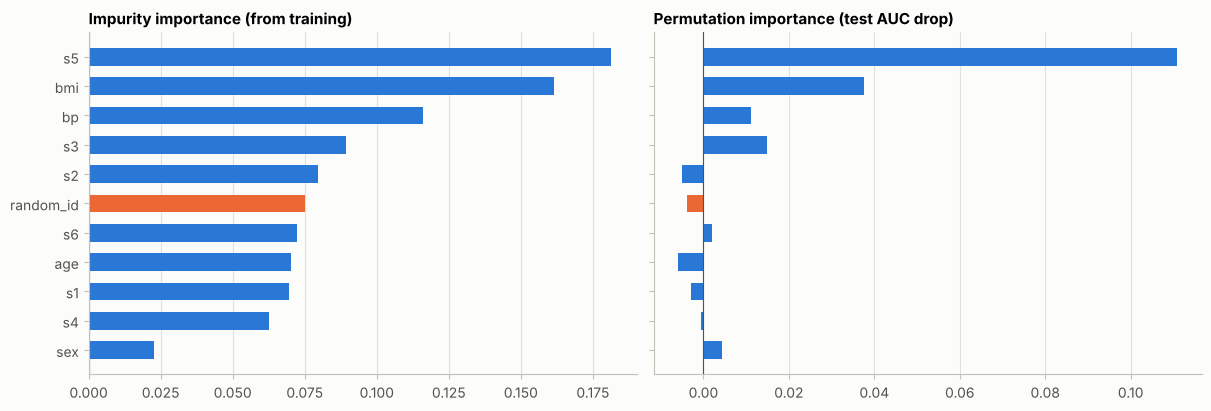

In [19]:
from sklearn.inspection import permutation_importance

# diabetes as a classification task : high vs low progression , plus one column of pure noise
Xq = Xd.copy()
Xq["random_id"] = np.random.default_rng(0).integers(0, 10_000, len(Xq))          # noise with MANY distinct values
yq = (yd > yd.median()).astype(int)
Xq_tr, Xq_te, yq_tr, yq_te = train_test_split(Xq, yq, test_size=0.3, stratify=yq, random_state=0)

rf = RandomForestClassifier(300, random_state=0).fit(Xq_tr, yq_tr)
impurity = pd.Series(rf.feature_importances_, index=Xq.columns).sort_values()
perm = permutation_importance(rf, Xq_te, yq_te, n_repeats=20, random_state=0, scoring="roc_auc")
perm_s = pd.Series(perm.importances_mean, index=Xq.columns)[impurity.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, s, title in [(axes[0], impurity, "Impurity importance (from training)"),
                     (axes[1], perm_s, "Permutation importance (test AUC drop)")]:
    colors = [SERIES[1] if c == "random_id" else SERIES[0] for c in s.index]
    ax.barh(s.index, s.values, color=colors, height=0.6)
    ax.axvline(0, color=INK2, linewidth=0.8)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
plt.show()
print("random_id : impurity rank", int((impurity >= impurity["random_id"]).sum()), "of", len(impurity),
      "| permutation AUC drop", round(perm_s["random_id"], 4))
print("test accuracy:", round(rf.score(Xq_te, yq_te), 3))

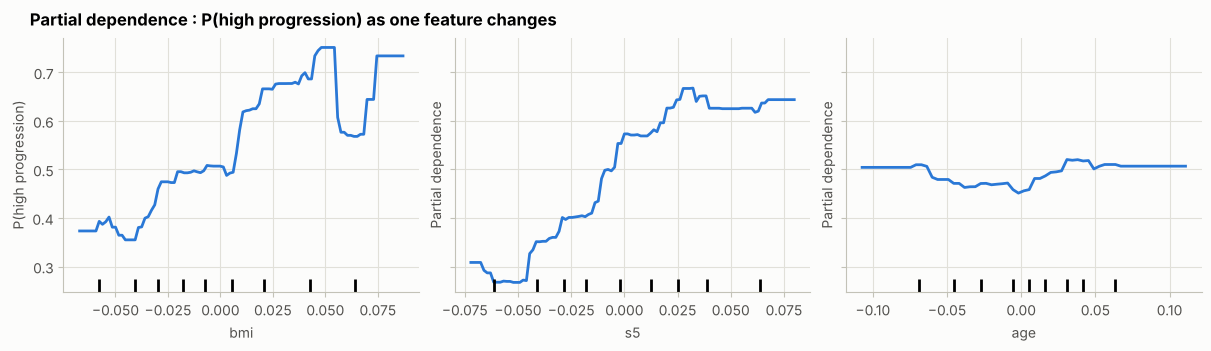

In [20]:
from sklearn.inspection import PartialDependenceDisplay

hgb = HistGradientBoostingClassifier(random_state=0).fit(Xd, yq)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
PartialDependenceDisplay.from_estimator(hgb, Xd, ["bmi", "s5", "age"], ax=axes,
                                        line_kw={"color": SERIES[0]}, kind="average",
                                        method="brute", response_method="predict_proba")
for ax in axes:
    ax.set_title("")
axes[0].set_ylabel("P(high progression)")
fig.suptitle("Partial dependence : P(high progression) as one feature changes", x=0.02, ha="left", fontweight="bold")
plt.show()

## 9. Unsupervised learning : no labels

         monthly_spend  visits_per_month
cluster                                 
0                386.3               9.0
1               1112.4               3.9
2                117.1               2.0


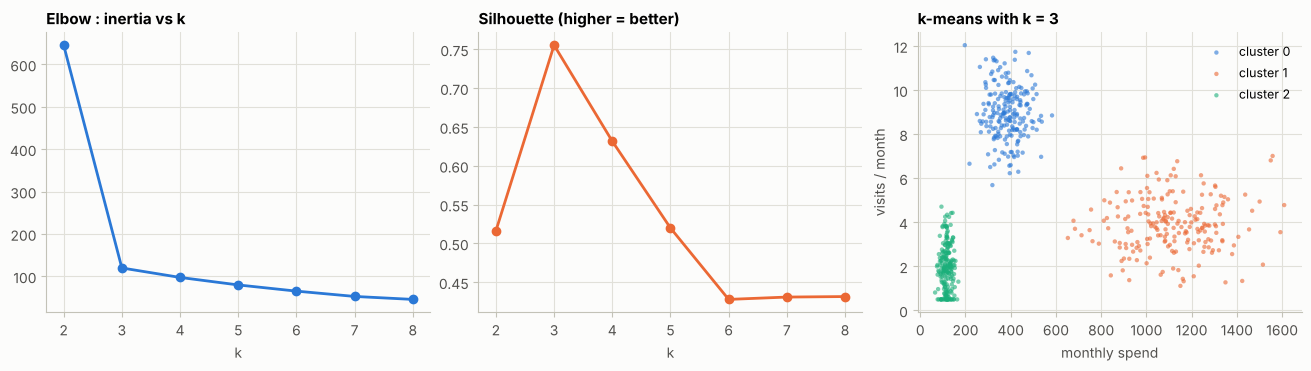

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(7)
centers = {"bargain hunters": (120, 2), "loyal regulars": (400, 9), "big spenders": (1100, 4)}
seg = pd.concat([pd.DataFrame({"monthly_spend": rng.normal(c[0], c[0] * 0.18, 200),
                               "visits_per_month": rng.normal(c[1], 1.2, 200).clip(0.5)}) for c in centers.values()],
                ignore_index=True)
Zs = StandardScaler().fit_transform(seg)

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=0).fit(Zs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Zs, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(ks, inertia, marker="o")
axes[0].set(title="Elbow : inertia vs k", xlabel="k")
axes[1].plot(ks, sil, marker="o", color=SERIES[1])
axes[1].set(title="Silhouette (higher = better)", xlabel="k")
best_k = list(ks)[int(np.argmax(sil))]
km = KMeans(best_k, n_init=10, random_state=0).fit(Zs)
for c in range(best_k):
    pts = seg[km.labels_ == c]
    axes[2].scatter(pts["monthly_spend"], pts["visits_per_month"], s=10, alpha=0.6, color=SERIES[c], edgecolor="none",
                    label=f"cluster {c}")
axes[2].set(title=f"k-means with k = {best_k}", xlabel="monthly spend", ylabel="visits / month")
axes[2].legend(loc="upper right")
plt.show()
print(seg.assign(cluster=km.labels_).groupby("cluster").mean().round(1))

DBSCAN clusters: 2 | points marked noise: 10


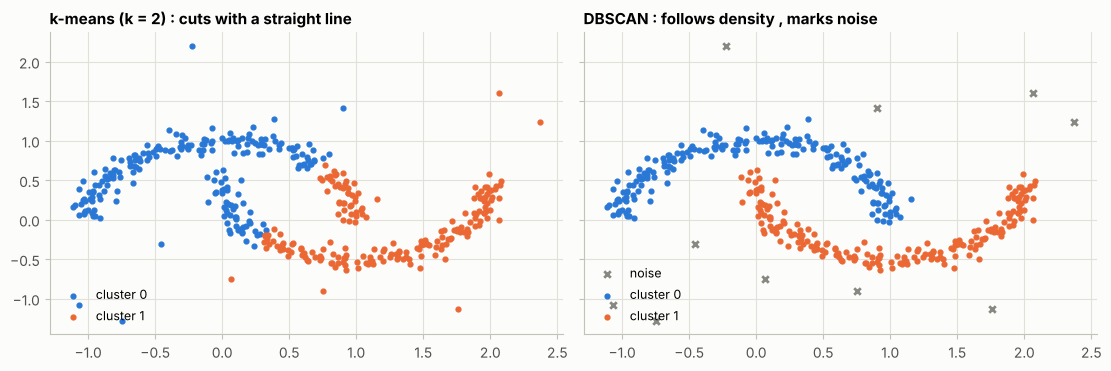

In [22]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

Xm, _ = make_moons(400, noise=0.07, random_state=0)
Xm = np.vstack([Xm, np.random.default_rng(2).uniform(-1.5, 2.5, (15, 2))])     # + 15 noise points
km_lab = KMeans(2, n_init=10, random_state=0).fit_predict(Xm)
db_lab = DBSCAN(eps=0.2, min_samples=6).fit_predict(Xm)                         # -1 = noise

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], km_lab, "k-means (k = 2) : cuts with a straight line"),
                       (axes[1], db_lab, "DBSCAN : follows density , marks noise")]:
    for c in sorted(set(lab)):
        color = MUTED if c == -1 else SERIES[c]
        ax.scatter(*Xm[lab == c].T, s=12 if c != -1 else 22, color=color, marker="x" if c == -1 else "o",
                   label="noise" if c == -1 else f"cluster {c}")
    ax.set_title(title)
    ax.legend(loc="lower left")
plt.show()
print("DBSCAN clusters:", len(set(db_lab) - {-1}), "| points marked noise:", int((db_lab == -1).sum()))

flagged: 11 | injected faults caught: 5 of 5


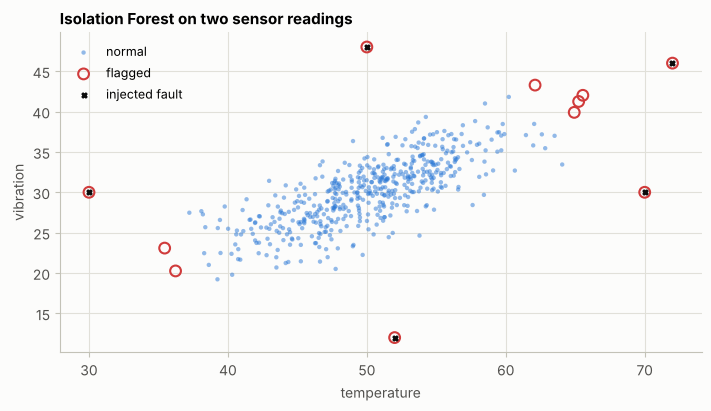

In [23]:
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(4)
normal = rng.multivariate_normal([50, 30], [[25, 15], [15, 16]], 500)          # e.g. motor temperature , vibration
faults = np.array([[70, 30], [50, 48], [30, 30], [72, 46], [52, 12]])
readings = np.vstack([normal, faults])

iso = IsolationForest(contamination=0.02, random_state=0).fit(readings)
score = -iso.score_samples(readings)                                             # higher = more anomalous
flag = iso.predict(readings) == -1

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(*readings[~flag].T, s=10, color=SERIES[0], alpha=0.5, edgecolor="none", label="normal")
ax.scatter(*readings[flag].T, s=60, facecolor="none", edgecolor="#d03b3b", linewidth=1.5, label="flagged")
ax.scatter(*faults.T, s=12, color=INK, marker="x", label="injected fault")
ax.set(title="Isolation Forest on two sensor readings", xlabel="temperature", ylabel="vibration")
ax.legend(loc="upper left")
plt.show()
print("flagged:", int(flag.sum()), "| injected faults caught:", int(flag[-5:].sum()), "of 5")

## 10. Saving a trained pipeline

In [24]:
import joblib
from pathlib import Path

out = Path("sklearn_demo")
out.mkdir(exist_ok=True)
final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
joblib.dump({"model": final, "sklearn": sklearn.__version__, "features": list(X.columns)}, out / "cancer_model.joblib")

bundle = joblib.load(out / "cancer_model.joblib")
print("saved with sklearn", bundle["sklearn"], "| features:", len(bundle["features"]))
print("same predictions:", np.array_equal(bundle["model"].predict(X_te), final.predict(X_te)))
print("file size:", round((out / "cancer_model.joblib").stat().st_size / 1024, 1), "KB")

saved with sklearn 1.9.1 | features: 30
same predictions: True
file size: 3.6 KB


## 11. Final project : an end-to-end churn model
    data -> split -> pipeline (impute , encode , scale) -> compare models with CV -> tune -> threshold ->
    ONE final test evaluation -> calibration -> explain -> save -> predict for a new customer

In [25]:
rng = np.random.default_rng(42)
n = 4000
plan = rng.choice(["basic", "pro", "premium"], n, p=[0.6, 0.3, 0.1])
tenure = rng.integers(1, 61, n)
calls = rng.poisson(np.where(plan == "basic", 2.0, 1.0))
spend = pd.Series(plan).map({"basic": 200, "pro": 450, "premium": 900}).to_numpy() * rng.lognormal(0, 0.25, n)
city = rng.choice(["Tehran", "Isfahan", "Shiraz", "Tabriz", "Mashhad"], n, p=[0.4, 0.15, 0.15, 0.15, 0.15])
logit = -1.0 + 0.45 * calls - 0.05 * tenure + 0.5 * (plan == "basic") + 0.8 * (calls >= 4) * (tenure < 12)
df = pd.DataFrame({"city": city, "age": rng.integers(18, 70, n).astype(float), "plan": plan,
                   "tenure_months": tenure, "monthly_spend": spend.round(0), "support_calls": calls,
                   "churned": (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)})
df.loc[rng.choice(n, 200, replace=False), "age"] = np.nan
df.loc[rng.choice(n, 150, replace=False), "city"] = np.nan

train_df, test_df = train_test_split(df, test_size=0.25, stratify=df["churned"], random_state=0)
Xc_tr, yc_tr = train_df.drop(columns="churned"), train_df["churned"]
Xc_te, yc_te = test_df.drop(columns="churned"), test_df["churned"]
print(df.shape, "| churn rate:", round(df["churned"].mean(), 3), "| missing:", df.isna().sum()[lambda s: s > 0].to_dict())

(4000, 7) | churn rate: 0.227 | missing: {'city': 150, 'age': 200}


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

num = ["age", "tenure_months", "monthly_spend", "support_calls"]
cat = ["city", "plan"]
prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat),
])
pipes = {
    "logistic": Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))]),
    "random forest": Pipeline([("prep", prep), ("clf", RandomForestClassifier(300, min_samples_leaf=10, random_state=0))]),
    "grad. boosting": Pipeline([("prep", prep), ("clf", HistGradientBoostingClassifier(random_state=0))]),
}
for name, p in pipes.items():
    s = cross_val_score(p, Xc_tr, yc_tr, cv=cv, scoring="roc_auc")
    print(f"{name:15s} CV AUC {s.mean():.3f} +- {s.std():.3f}")

logistic        CV AUC 0.764 +- 0.026
random forest   CV AUC 0.750 +- 0.027
grad. boosting  CV AUC 0.713 +- 0.025


In [27]:
search = GridSearchCV(pipes["grad. boosting"],
                      {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 3, 5], "clf__min_samples_leaf": [20, 50]},
                      cv=cv, scoring="roc_auc").fit(Xc_tr, yc_tr)
print("best:", search.best_params_, "| CV AUC:", round(search.best_score_, 3))

finalists = {"logistic": pipes["logistic"], "tuned grad. boosting": search.best_estimator_}
cv_auc = {k: cross_val_score(m, Xc_tr, yc_tr, cv=cv, scoring="roc_auc").mean() for k, m in finalists.items()}
winner = max(cv_auc, key=cv_auc.get)
print({k: round(float(v), 3) for k, v in cv_auc.items()}, "-> winner:", winner)

final_model = TunedThresholdClassifierCV(clone(finalists[winner]), scoring="f1", cv=5).fit(Xc_tr, yc_tr)
print("threshold chosen on TRAIN by CV:", round(final_model.best_threshold_, 3))

best: {'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__min_samples_leaf': 50} | CV AUC: 0.759
{'logistic': 0.764, 'tuned grad. boosting': 0.759} -> winner: logistic
threshold chosen on TRAIN by CV: 0.204


TEST  AUC 0.759 | precision 0.367 | recall 0.736 | F1 0.49


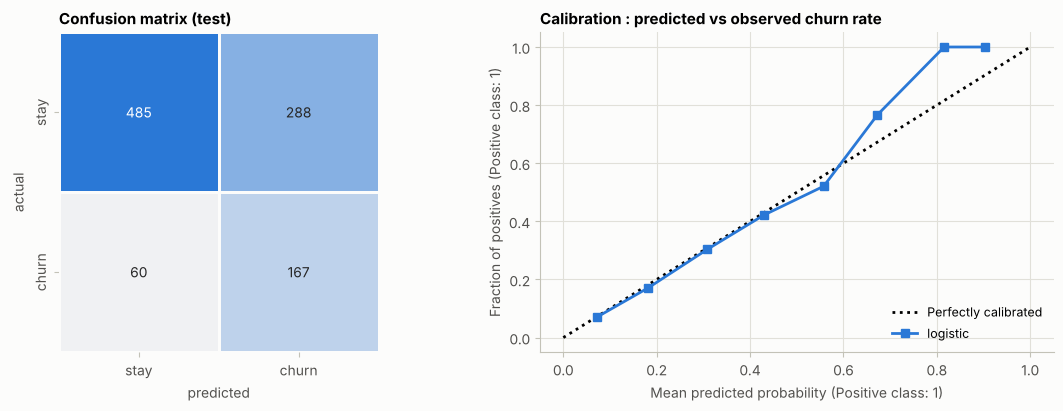

In [28]:
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.calibration import CalibrationDisplay

proba = final_model.predict_proba(Xc_te)[:, 1]          # the test set , used ONCE
pred = final_model.predict(Xc_te)
print("TEST  AUC", round(roc_auc_score(yc_te, proba), 3), "| precision", round(precision_score(yc_te, pred), 3),
      "| recall", round(recall_score(yc_te, pred), 3), "| F1", round(f1_score(yc_te, pred), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(yc_te, pred), annot=True, fmt="d", cbar=False, square=True, linewidths=2,
            linecolor=SURFACE, cmap=sns.light_palette(SERIES[0], as_cmap=True),
            xticklabels=["stay", "churn"], yticklabels=["stay", "churn"], ax=axes[0])
axes[0].set(title="Confusion matrix (test)", xlabel="predicted", ylabel="actual")
CalibrationDisplay.from_predictions(yc_te, proba, n_bins=8, ax=axes[1], color=SERIES[0], name=winner)
axes[1].set(title="Calibration : predicted vs observed churn rate")
plt.show()

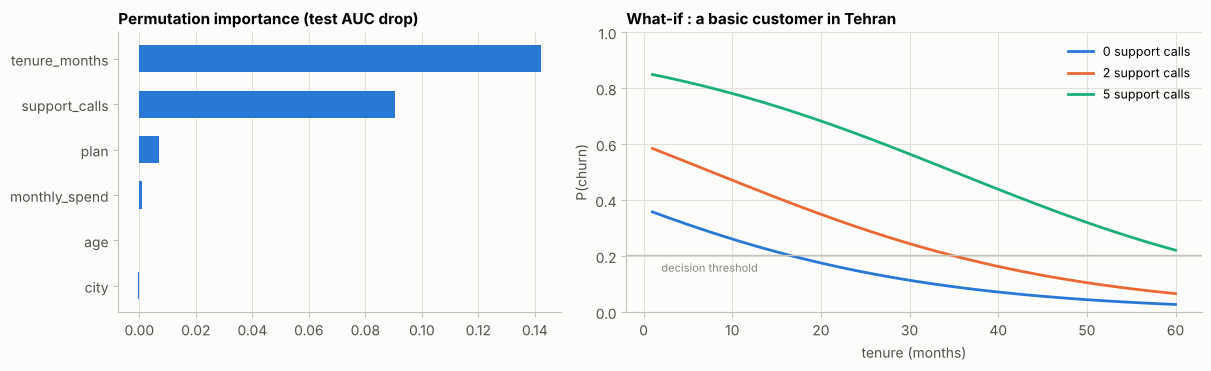

In [29]:
perm = permutation_importance(final_model, Xc_te, yc_te, n_repeats=15, random_state=0, scoring="roc_auc")
imp = pd.Series(perm.importances_mean, index=Xc_te.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].barh(imp.index, imp.values, color=SERIES[0], height=0.6)
axes[0].set(title="Permutation importance (test AUC drop)")
axes[0].grid(axis="y", visible=False)

grid_t = np.arange(1, 61)
for k, calls_v in enumerate([0, 2, 5]):
    probe = pd.DataFrame({"city": "Tehran", "age": 35.0, "plan": "basic", "tenure_months": grid_t,
                          "monthly_spend": 200.0, "support_calls": calls_v})
    axes[1].plot(grid_t, final_model.predict_proba(probe)[:, 1], color=SERIES[k], label=f"{calls_v} support calls")
axes[1].axhline(final_model.best_threshold_, color=AXIS, linewidth=1)
axes[1].text(2, final_model.best_threshold_ - 0.06, "decision threshold", ha="left", color=MUTED, fontsize=8)
axes[1].set(title="What-if : a basic customer in Tehran", xlabel="tenure (months)", ylabel="P(churn)", ylim=(0, 1))
axes[1].legend(loc="upper right")
plt.show()

In [30]:
joblib.dump({"model": final_model, "sklearn": sklearn.__version__, "columns": list(Xc_tr.columns)}, out / "churn_model.joblib")
service = joblib.load(out / "churn_model.joblib")

new_customers = pd.DataFrame([
    {"city": "Tehran", "age": 29, "plan": "basic", "tenure_months": 3, "monthly_spend": 190, "support_calls": 5},
    {"city": "Shiraz", "age": 51, "plan": "premium", "tenure_months": 48, "monthly_spend": 950, "support_calls": 0},
    {"city": "Kerman", "age": None, "plan": "pro", "tenure_months": 14, "monthly_spend": 470, "support_calls": 2},
])[service["columns"]]
out_df = new_customers.assign(p_churn=service["model"].predict_proba(new_customers)[:, 1].round(3),
                              action=np.where(service["model"].predict(new_customers) == 1, "call now", "-"))
print(out_df)

CLEANUP = True
if CLEANUP:
    for f in out.iterdir():
        f.unlink()
    out.rmdir()

     city   age     plan  tenure_months  monthly_spend  support_calls  p_churn    action
0  Tehran  29.0    basic              3            190              5    0.836  call now
1  Shiraz  51.0  premium             48            950              0    0.021         -
2  Kerman   NaN      pro             14            470              2    0.347  call now


## Exercises
1. in section 1 , fit `LogisticRegression` on the UNSCALED data : what warning do you get and why ?
2. repeat the leakage experiment of section 2 with `StandardScaler` instead of `SelectKBest` : is the leak large ? why is feature selection so much worse ?
3. in section 3 , use `RidgeCV` and `LassoCV` to choose alpha automatically ; compare their CV RMSE.
4. in section 4 , which model is the fastest to train and which is the slowest ? would you pay that cost for the difference in AUC ?
5. draw a depth-3 tree of the cancer data with `plot_tree` and translate it into `if / else` rules.
6. in section 6 , why is the best SVM cell surrounded by good cells but the corners are bad ? what do large `gamma` values do ?
7. in section 7 , use `scoring="recall"` with a minimum precision constraint : how would you do it ?
8. in section 9 , run k-means WITHOUT scaling : what happens to the clusters and why ?
9. in the final project , add `TargetEncoder` for `city` ; does it help ? explain with the permutation importance of `city`.
10. the new customer from Kerman has a city never seen in training : what did the pipeline do with it ?